# 29 — Metric Validity & Statistical Uncertainty Audit
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 8 (History-Intervention Validity and Mechanism Diagnostics)  
**Status:** `Validated Audit`  

### Forensic Objectives:
1. Audit statistical uncertainty intervals on independent scenarios ($N=20$).
2. Refute naive interpretation of degenerate empirical bootstrap [0, 0] intervals.
3. Establish exact construct validity boundaries across evaluation metrics.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
import numpy as np

# Exact Wilson Score Interval calculation
def wilson_ci(k: int, n: int, confidence: float = 0.95):
    z = 1.95996  # 95% normal quantile
    p_hat = k / n
    denominator = 1 + z**2 / n
    centre_adj = (p_hat + z**2 / (2 * n)) / denominator
    spread = z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n)) / n) / denominator
    lower = max(0.0, centre_adj - spread)
    upper = min(1.0, centre_adj + spread)
    return lower, upper

summary_path = os.path.join(repo_root, "results", "intervention_diagnostics", "diagnostic_summary.json")
with open(summary_path) as f:
    diag_summary = json.load(f)

print(f"{'Policy Checkpoint':32s} | Disc Scenarios | Disc Rate | Wilson 95% Confidence Interval")
print("-" * 85)
for p_name, s in diag_summary["policy_summaries"].items():
    k = s["discordant_scenarios"]
    n = s["num_scenarios"]
    low, high = wilson_ci(k, n)
    print(f"{p_name:32s} | {k:2d} / {n:2d}        | {s['discordance_rate']*100:5.1f}%    | [{low*100:5.1f}%, {high*100:5.1f}%]")


Policy Checkpoint                | Disc Scenarios | Disc Rate | Wilson 95% Confidence Interval
-------------------------------------------------------------------------------------
recovery_augmented_gru_seed42    |  0 / 20        |   0.0%    | [  0.0%,  16.1%]
recovery_augmented_gru_seed123   |  0 / 20        |   0.0%    | [  0.0%,  16.1%]
recovery_augmented_gru_seed456   |  2 / 20        |  10.0%    | [  2.8%,  30.1%]
recovery_augmented_mlp_seed42    |  0 / 20        |   0.0%    | [  0.0%,  16.1%]


### 1. Metric Construct Validity Matrix (Figure 56 & 57)

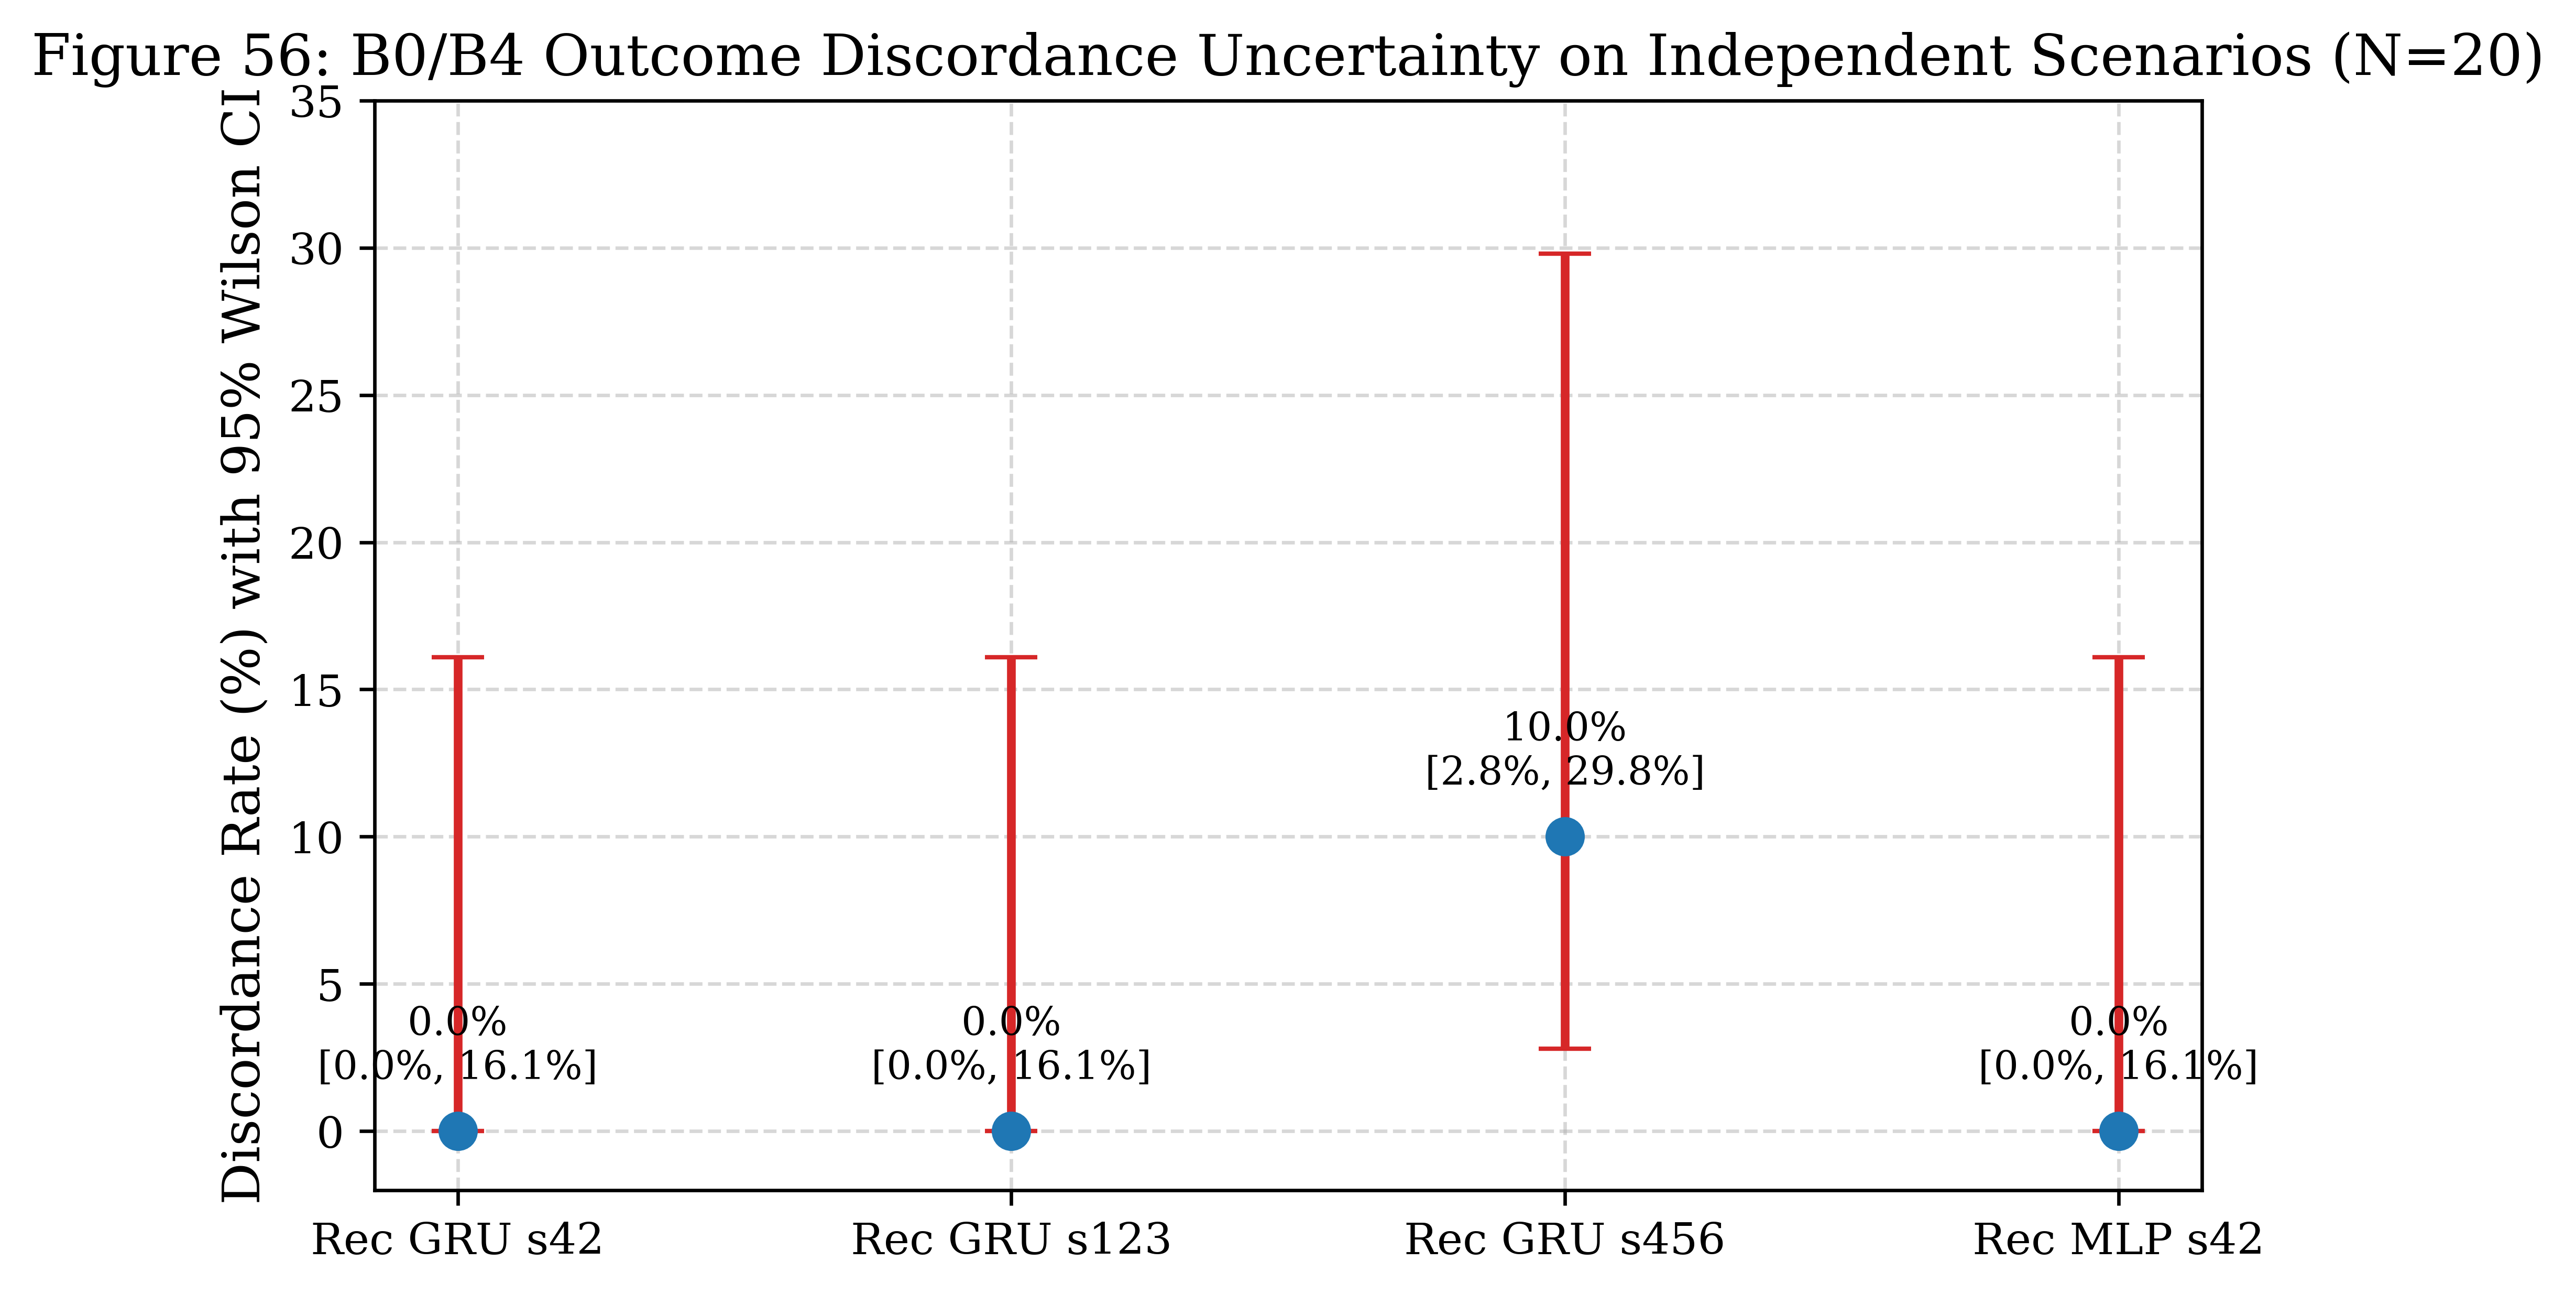

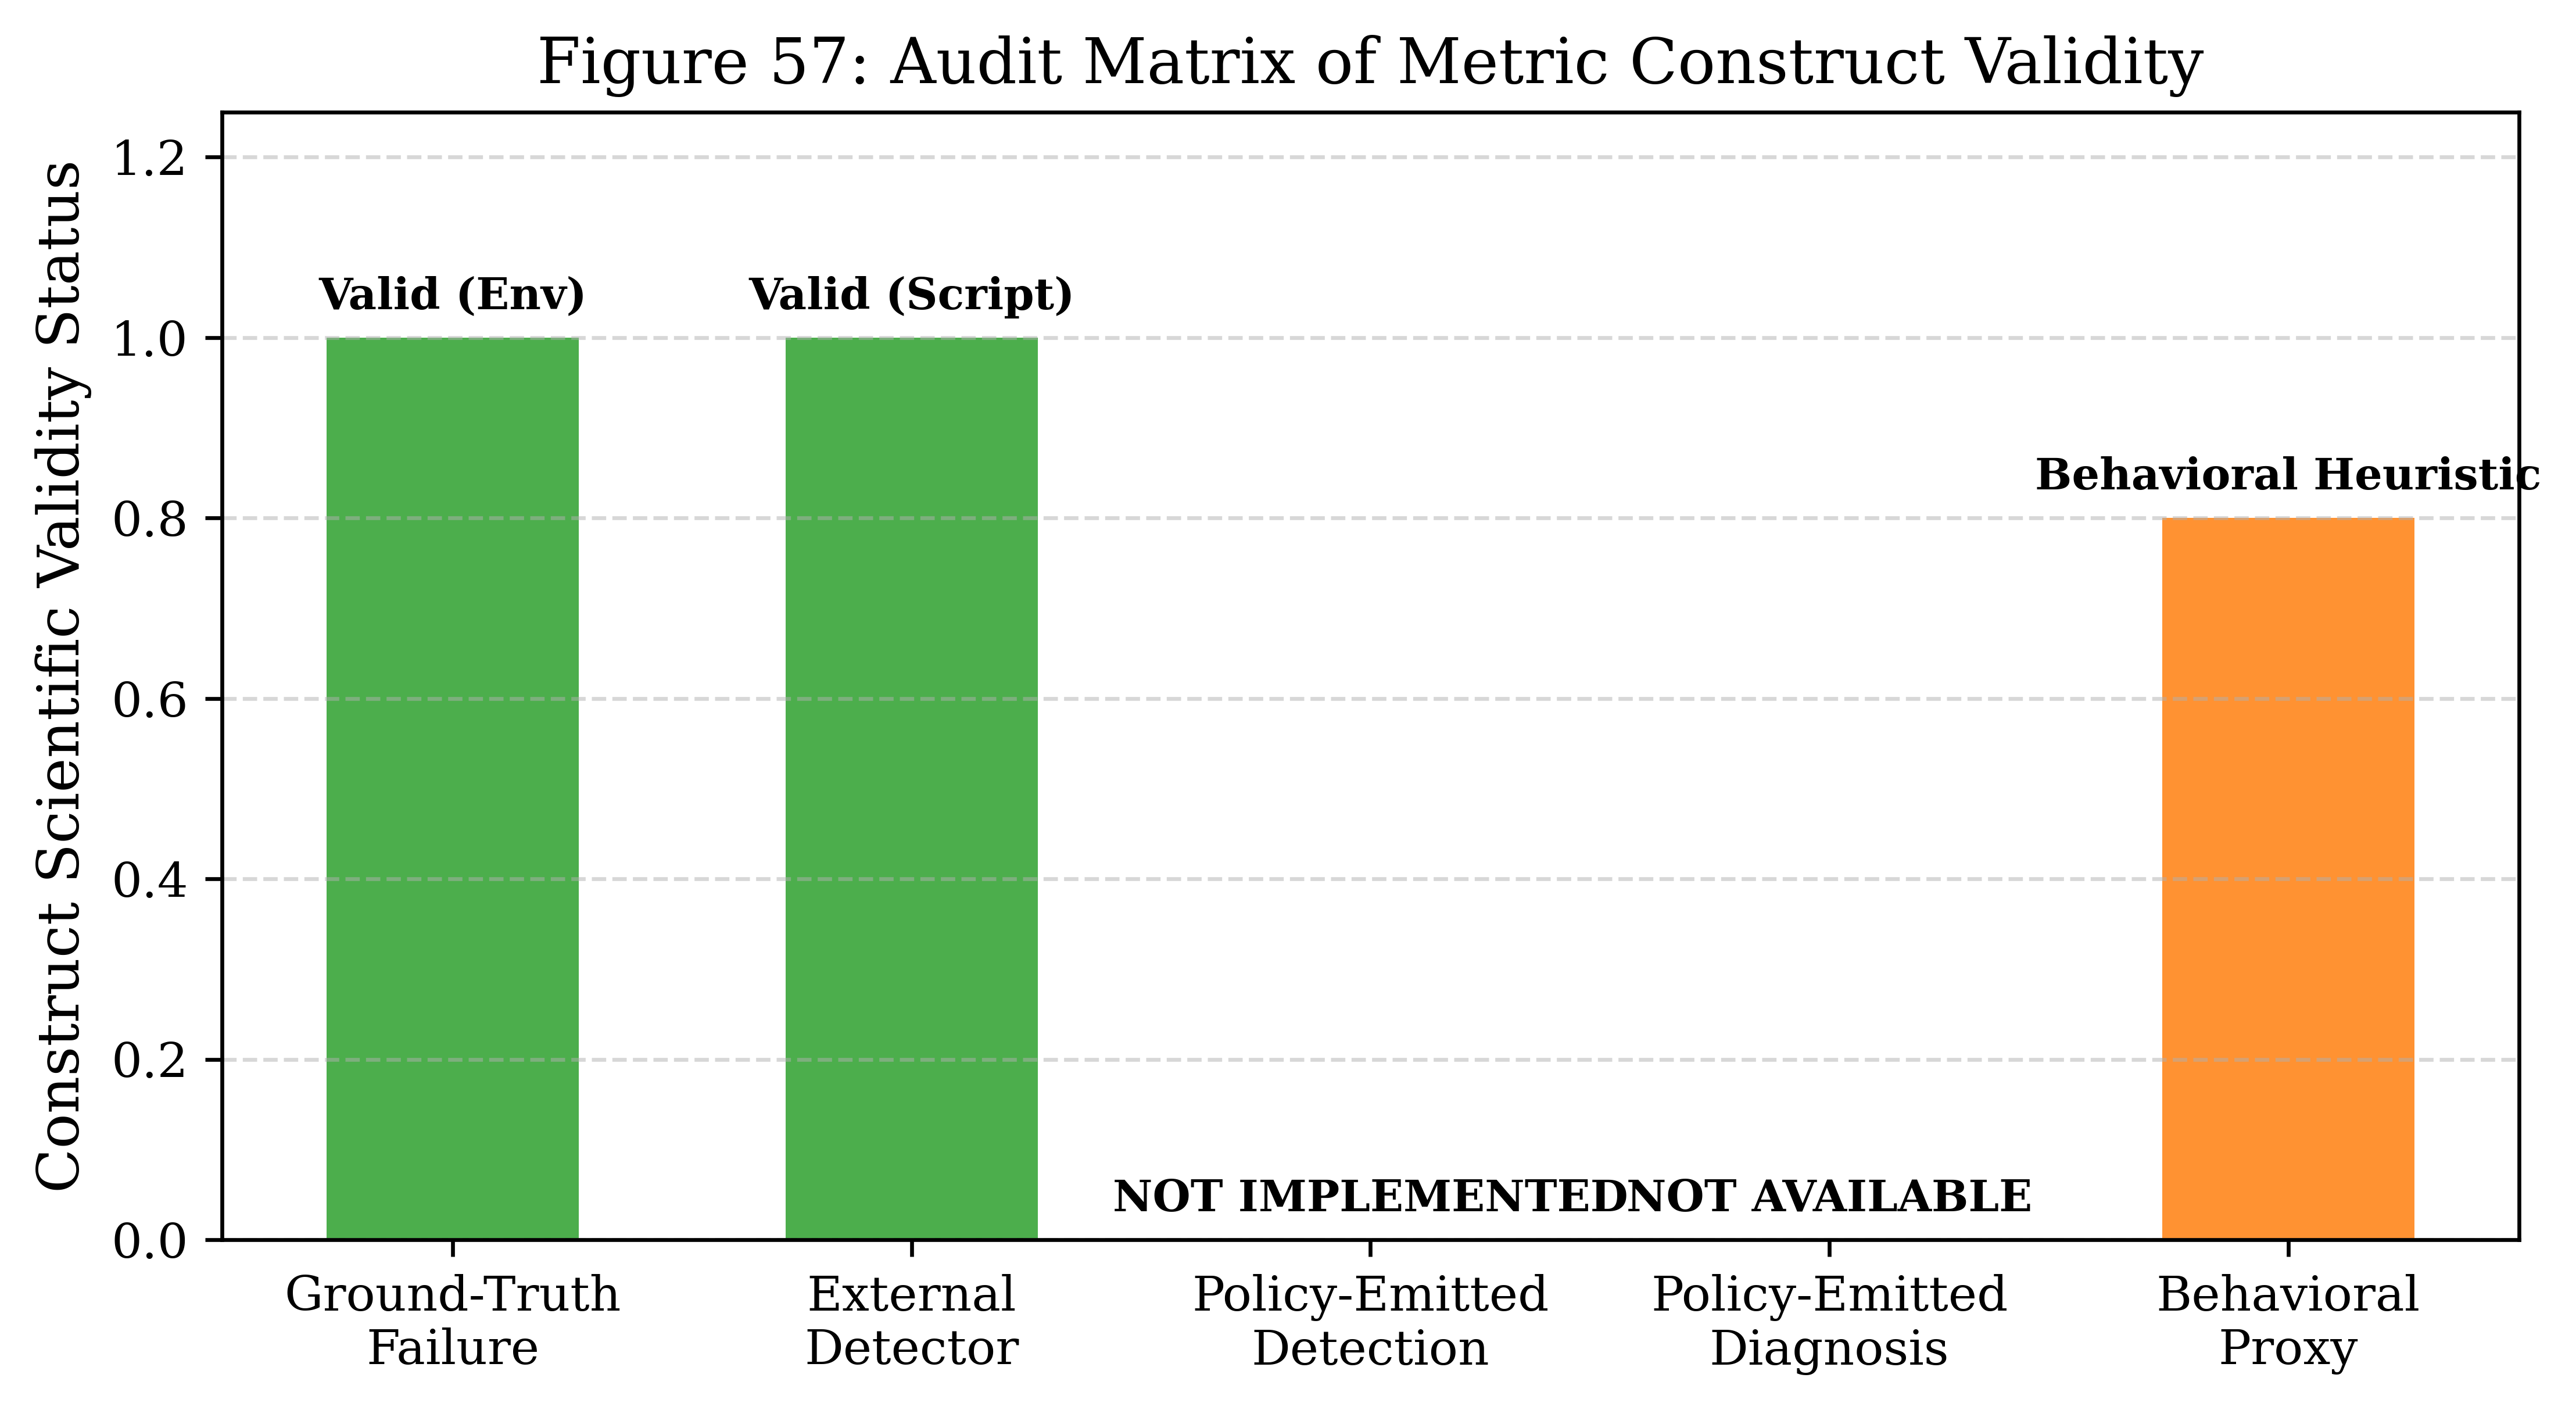

In [2]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig56_discordance_rate_uncertainty_cis.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig57_metric_validity_construct_matrix.png")))


### Phase 8 Completion Gate
`Phase 8 diagnostic work is complete. Official benchmark experiments remain paused pending explicit user approval.`